# 05 · Evaluation and error analysis

This notebook runs the LoRA model on the held-out test set once and compares it with the two baselines:

| system | what it is |
|---|---|
| **TF-IDF + LogReg** | char + word n-grams, linear classifier (notebook 02) |
| **Zero-shot** | Qwen3-4B-Instruct prompted, no training (notebook 03) |
| **LoRA** | the same Qwen3-4B, LoRA-tuned with a classification head (notebook 04) |

All three are scored on the **same 4,996 test comments** with **macro-F1**. Every score comes with a 95% bootstrap confidence interval, and differences are checked with a paired bootstrap.

In [1]:
import sys
sys.path.insert(0, "../src")

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from darija_sentiment.config import ADAPTER_DIR, LABELS, METRICS_DIR, RESULTS_DIR
from darija_sentiment.data import load_splits
from darija_sentiment.llm import load_finetuned, predict_proba
from darija_sentiment.metrics import (
    bootstrap_ci, evaluate_by_script, load_predictions, macro_f1, paired_bootstrap, plot_confusion,
    save_figure, save_metrics, save_predictions,
)

pd.set_option("display.max_colwidth", 110)
ID2NAME = dict(enumerate(LABELS))
splits = load_splits()
val, test = splits["val"], splits["test"]

## Run the fine-tuned model on the test set

The model is loaded the same way a user of the published adapter would load it: base model from the Hub plus `PeftModel.from_pretrained(adapter)`.

In [2]:
model, tokenizer = load_finetuned(ADAPTER_DIR)

val_proba = predict_proba(model, tokenizer, val["text"].tolist())
val_macro_f1 = evaluate_by_script(val.assign(pred=val_proba.argmax(1))).loc["all", "macro_f1"]
print(f"validation macro-F1 (should match the best checkpoint): {val_macro_f1:.4f}")

start = time.time()
proba = predict_proba(model, tokenizer, test["text"].tolist())
seconds = time.time() - start
print(f"{len(test):,} test comments in {seconds:.0f} s ({len(test) / seconds:.1f} comments/s)")

lora = test.assign(pred=proba.argmax(1), p_negative=proba[:, 0], p_neutral=proba[:, 1], p_positive=proba[:, 2])
lora_by_script = evaluate_by_script(lora)
lora_ci = bootstrap_ci(lora["label"], lora["pred"])
save_predictions(lora, "lora")
save_metrics({
    "system": "LoRA fine-tuned Qwen3-4B-Instruct-2507",
    "val_macro_f1": val_macro_f1,
    "test": lora_by_script.to_dict(orient="index"),
    "test_macro_f1_ci95": lora_ci,
    "comments_per_second": len(test) / seconds,
}, "lora")
lora_by_script.round(4)

validation macro-F1 (should match the best checkpoint): 0.8000


4,996 test comments in 48 s (103.8 comments/s)


,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive,n
subset,,,,,,
all,0.7947,0.8223,0.8290,0.6644,0.8907,4996
arabic,0.7966,0.8214,0.8340,0.6685,0.8872,4306
latin,0.7683,0.8291,0.7956,0.6010,0.9083,632
mixed,0.8141,0.8400,0.7059,0.8095,0.9268,50


In [3]:
del model
torch.cuda.empty_cache()

## Head-to-head comparison

In [4]:
SYSTEMS = {"tfidf_logreg": "TF-IDF + LogReg", "zero_shot": "Zero-shot Qwen3-4B", "lora": "LoRA Qwen3-4B"}
preds = {key: load_predictions(key) for key in SYSTEMS}
metrics = {key: json.loads((METRICS_DIR / f"{key}.json").read_text(encoding="utf-8")) for key in SYSTEMS}

# All prediction files must describe the same test comments in the same order.
assert all((p["id"].values == test["id"].values).all() for p in preds.values())

rows = []
for key, name in SYSTEMS.items():
    t = metrics[key]["test"]
    lo, hi = metrics[key]["test_macro_f1_ci95"]
    rows.append({
        "system": name,
        "macro-F1": t["all"]["macro_f1"],
        "95% CI": f"{lo:.3f}–{hi:.3f}",
        "accuracy": t["all"]["accuracy"],
        "F1 neg": t["all"]["f1_negative"],
        "F1 neu": t["all"]["f1_neutral"],
        "F1 pos": t["all"]["f1_positive"],
        "macro-F1 Arabic script": t["arabic"]["macro_f1"],
        "macro-F1 Latin script": t["latin"]["macro_f1"],
    })
comparison = pd.DataFrame(rows).set_index("system")
comparison.round(3)

,macro-F1,95% CI,accuracy,F1 neg,F1 neu,F1 pos,macro-F1 Arabic script,macro-F1 Latin script
system,,,,,,,,
TF-IDF + LogReg,0.762,0.749–0.774,0.796,0.797,0.611,0.877,0.766,0.715
Zero-shot Qwen3-4B,0.635,0.620–0.649,0.700,0.696,0.410,0.799,0.640,0.569
LoRA Qwen3-4B,0.795,0.783–0.806,0.822,0.829,0.664,0.891,0.797,0.768


### Is the gap real? Paired bootstrap

The three systems are scored on the same comments, so I resample the test set 1,000 times and recompute the *difference* in macro-F1 on each resample. If the 95% interval of the difference excludes 0, the gap is unlikely to be luck in which comments ended up in the test set.

In [5]:
paired = pd.DataFrame({
    f"LoRA vs {SYSTEMS[other]}": paired_bootstrap(test["label"], preds["lora"]["pred"], preds[other]["pred"])
    for other in ["tfidf_logreg", "zero_shot"]
}).T
paired.round(4)

,mean_diff,ci_low,ci_high,p_a_not_better
LoRA vs TF-IDF + LogReg,0.0327,0.0204,0.0439,0.0
LoRA vs Zero-shot Qwen3-4B,0.1597,0.1441,0.1753,0.0


**LoRA wins, and the gap is real.** It scores 0.795 macro-F1, against 0.762 for TF-IDF and 0.635 for zero-shot. The paired bootstrap puts the gain over TF-IDF at **+3.3 points (95% CI +2.0 to +4.4)**, and LoRA comes out ahead on every one of the 1,000 resamples. Over zero-shot the gain is **+16 points**. That's the same base model with the same weights, plus 33M trained parameters and about an hour on one GPU.

Two things stand out. First, the TF-IDF baseline is strong: a model trained in 15 seconds on a CPU comes within 3.3 points. Second, the zero-shot result is weak: a 4B instruction-tuned model that reads Arabic loses to n-grams by 13 points. Understanding the language isn't enough. The model also has to learn what *this dataset* means by neutral, and that comes from labelled examples, not from a prompt.

## Confusion matrices

Rows are normalised: each row shows where the comments of one *true* class end up. Raw counts are in brackets.

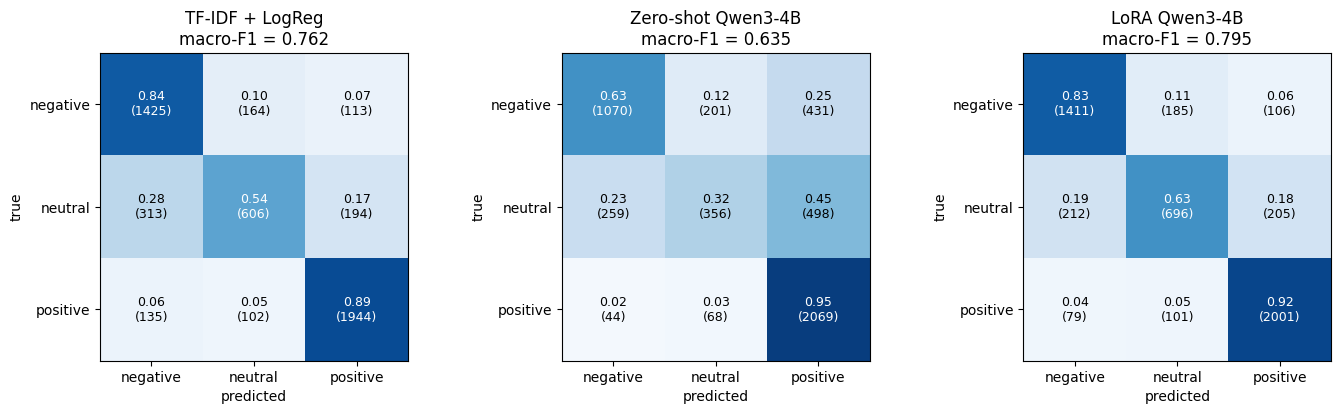

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (key, name) in zip(axes, SYSTEMS.items()):
    p = preds[key]
    plot_confusion(p["label"], p["pred"], f"{name}\nmacro-F1 = {metrics[key]['test']['all']['macro_f1']:.3f}", ax=ax)
fig.tight_layout()
save_figure(fig, "confusion_matrices")

## Arabic script vs. Latin script

,TF-IDF + LogReg,Zero-shot Qwen3-4B,LoRA Qwen3-4B,n (test)
arabic,0.766,0.640,0.797,4306
latin,0.715,0.569,0.768,632
mixed,0.797,0.683,0.814,50


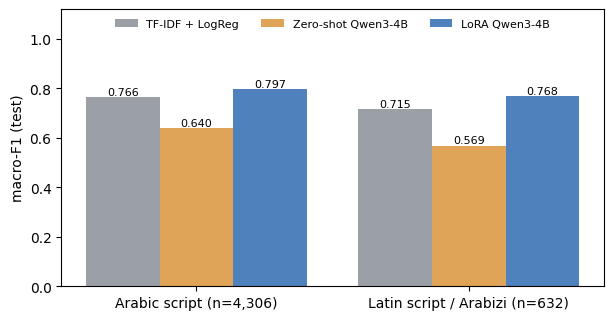

In [7]:
script_table = pd.DataFrame({
    name: {s: metrics[key]["test"][s]["macro_f1"] for s in ["arabic", "latin", "mixed"]} for key, name in SYSTEMS.items()
})
script_table["n (test)"] = [int(metrics["lora"]["test"][s]["n"]) for s in script_table.index]
display(script_table.round(3))

colors = ["#9aa0a6", "#e0a458", "#4f81bd"]
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(2)
for i, (key, name) in enumerate(SYSTEMS.items()):
    vals = [metrics[key]["test"][s]["macro_f1"] for s in ["arabic", "latin"]]
    bars = ax.bar(x + (i - 1) * 0.27, vals, 0.27, label=name, color=colors[i])
    ax.bar_label(bars, fmt="%.3f", fontsize=8)
n = {s: int(metrics["lora"]["test"][s]["n"]) for s in ["arabic", "latin"]}
ax.set_xticks(x, [f"Arabic script (n={n['arabic']:,})", f"Latin script / Arabizi (n={n['latin']:,})"])
ax.set_ylabel("macro-F1 (test)"); ax.set_ylim(0, 1.12); ax.legend(loc="upper center", ncol=3, fontsize=8, frameon=False)
save_figure(fig, "f1_by_script")

The Latin-script subset is small (632 comments), so its scores are noisier. Bootstrap intervals per script:

In [8]:
ci_rows = {}
for key, name in SYSTEMS.items():
    p = preds[key]
    for s in ["arabic", "latin"]:
        part = p[p["script"] == s]
        lo, hi = bootstrap_ci(part["label"], part["pred"])
        ci_rows[(name, s)] = f"{lo:.3f}–{hi:.3f}"
pd.Series(ci_rows).unstack()

,arabic,latin
LoRA Qwen3-4B,0.784–0.809,0.727–0.804
TF-IDF + LogReg,0.751–0.779,0.673–0.754
Zero-shot Qwen3-4B,0.625–0.654,0.524–0.610


**The gap is largest on Arabizi.** On Latin-script comments LoRA beats TF-IDF by 5.3 points (0.768 vs 0.715), compared with 3.1 points on Arabic script. Free spelling hurts n-grams most in Arabizi, where `bezaf`, `bzaf` and `bzzaf` are different features. Zero-shot is weakest on Arabizi (0.569), so the base model knows much less Latin-script Darija than Arabic-script Darija. Fine-tuning closes most of that gap: LoRA's Latin-script score is only 3 points below its Arabic-script score.

With only 632 Latin-script test comments the intervals are wide and overlap a little (LoRA 0.727–0.804, TF-IDF 0.673–0.754), so the exact size of the Arabizi gap should be read with some care.

## Does comment length matter?

In [9]:
lengths = test["text"].str.split().str.len()
buckets = pd.cut(lengths, [0, 3, 7, 15, 30, 10_000], labels=["1–3", "4–7", "8–15", "16–30", "31+"])
length_table = pd.DataFrame({
    name: preds[key].groupby(buckets.values, observed=True)[["label", "pred"]].apply(
        lambda g: macro_f1(g["label"], g["pred"]))
    for key, name in SYSTEMS.items()
})
length_table["n"] = buckets.value_counts().reindex(length_table.index)
length_table.index.name = "words"
length_table.round(3)

,TF-IDF + LogReg,Zero-shot Qwen3-4B,LoRA Qwen3-4B,n
words,,,,
1–3,0.753,0.581,0.798,672
4–7,0.765,0.646,0.790,1568
8–15,0.764,0.636,0.804,1566
16–30,0.750,0.602,0.779,857
31+,0.727,0.591,0.770,333


LoRA leads in every length bucket. Its biggest lead is on the **shortest comments** (1–3 words: 0.798 vs 0.753). With so little text an n-gram model has almost nothing to go on, while a pretrained model already knows what the few words mean. All systems lose a few points on long comments (31+ words), which often mix praise and criticism in the same message.

## Error analysis of the LoRA model

In [10]:
errors = lora[lora["pred"] != lora["label"]].copy()
errors["true"] = errors["label"].map(ID2NAME)
errors["predicted"] = errors["pred"].map(ID2NAME)
errors["confidence"] = proba[errors.index].max(1)
print(f"{len(errors):,} errors out of {len(lora):,} ({len(errors) / len(lora):.1%})")
errors.groupby(["true", "predicted"]).size().sort_values(ascending=False).to_frame("count")

888 errors out of 4,996 (17.8%)


count
true     predicted       
neutral  negative     212
         positive     205
negative neutral      185
         positive     106
positive neutral      101
         negative      79

**Neutral is involved in 703 of the 888 errors (79%)**, as either the true or the predicted class. Confusing negative with positive outright is comparatively rare (185 errors), so the model almost always gets the *polarity* right and struggles with whether a comment has an opinion at all.

### Most confident mistakes

When a well-trained model is very confident and still "wrong", the gold label is often the problem. These are worth reading one by one.

In [11]:
errors.sort_values("confidence", ascending=False)[["text", "script", "true", "predicted", "confidence"]].head(25)

,text,script,true,predicted,confidence
375,اين هيا الفحوصات PCR? غير موجودة بولاية باتنة,arabic,negative,neutral,0.998418
1817,كبير وجايح وكل من يشجعه على ذلك,arabic,neutral,negative,0.997798
503,ديرنا فيديو كيفاه نتقنوها نستعملوها فحوايج ايجابية لي متفق يدير جام,arabic,positive,neutral,0.997033
1701,اسئلتكم لم تكن في المستوى قتلتوهم بواش كونلك ولدك واش كونلك باك حتى ماعرفوش واش يجوبكم,arabic,neutral,negative,0.996992
1431,😋😋شهيتني يعطيك الصحة 💝,arabic,neutral,positive,0.996976
2364,كاين مشكل في هاتف ريدمي نوت 8 في إلتقاط شبكة الويفي وضعفها,arabic,negative,neutral,0.996226
2135,لا لا لا لا لدستور العار والفجار,arabic,neutral,negative,0.996063
2778,راك دور تم برك راك تفقد في المصداقية نتاعك,arabic,neutral,negative,0.995858
2674,انا نحبكم بزاف جربنا معمول الورقة روعة روعة,arabic,neutral,positive,0.995036
4063,اي يرحو يعطو في زوج .. انا عجبتني لبنية لجالسة فلخلف تبان آلله يبارك,arabic,negative,positive,0.994965


I read these 25 one by one. Roughly:

- **About 17 look like annotation errors.** "انا نحبكم بزاف جربنا معمول الورقة روعة روعة" (*I love you so much, we tried the recipe, amazing amazing*) is gold **neutral**. So are "يسقط جنرالات الجزائر العملاء…" (*down with the traitor generals…*), "لا لا لا لا لدستور العار" (*no, no, no to the constitution of shame*), "😋😋شهيتني يعطيك الصحة 💝" (*you made me hungry, thank you*) and the Arabizi "Khlas wahad mawala ihabak… nti machi moslima" (*nobody loves you anymore… you're not a Muslim*). Blessings such as "الله يوفقك يارب" and "ربي طول ويبارك في عمرك" are gold neutral too, although most blessings in the training data are labelled positive.
- **About 3 are real model mistakes**, all of the same kind: **complaints phrased as questions or as calm statements.** Examples are "اين هيا الفحوصات PCR? غير موجودة بولاية باتنة" (*where are the PCR tests? there are none in Batna*), "وين راه الزين انا لا اراه" (*where's the beauty? I don't see it*) and "Cette enseignante a besoin de cours de psychologie." The model has learned that a question usually means neutral (60% of training comments with a question mark are neutral) and misses the complaint underneath.
- **The rest are genuinely ambiguous**, for example a factual report of a phone bug that the annotator read as a complaint.

So the model's most confident errors are mostly cases where it is right and the label isn't. That matters for how to read the scores: a sizeable part of the remaining 18% error is noise in the test labels, not something more training would fix.

### How consistent are the labels?

To check this beyond a handful of examples, I looked at how the annotators labelled recurring types of comment across the whole dataset:

In [12]:
all_data = pd.concat(splits.values())
patterns = {
    "condolences (يرحم, rahma, yarhm)": r"يرحم|رحمه الله|رحمة الله|y[ae]r[h7]m|rahma|ra7ma",
    "blessings (يحفظ, يبارك, rabi y…)": r"يحفظ|يبارك|يخليك|ربي يوفق|الله يوفق|rabi y|rebi y",
    "question mark": r"[?؟]",
    "crying emoji 😭 😢": r"😭|😢",
    "laughter (ههه, hhh, 😂, 🤣)": r"ههه|hhh|😂|🤣",
}
consistency = pd.DataFrame({
    name: all_data.loc[all_data["text"].str.contains(rx, case=False, regex=True), "label"]
                  .map(ID2NAME).value_counts(normalize=True).reindex(LABELS).round(2)
    for name, rx in patterns.items()
}).T
consistency["n"] = [all_data["text"].str.contains(rx, case=False, regex=True).sum() for rx in patterns.values()]
consistency.loc["all comments"] = [*all_data["label"].map(ID2NAME).value_counts(normalize=True).reindex(LABELS).round(2), len(all_data)]
consistency

label,negative,neutral,positive,n
"condolences (يرحم, rahma, yarhm)",0.20,0.14,0.66,1762.0
"blessings (يحفظ, يبارك, rabi y…)",0.03,0.05,0.92,3409.0
question mark,0.34,0.60,0.06,1557.0
crying emoji 😭 😢,0.30,0.21,0.48,538.0
"laughter (ههه, hhh, 😂, 🤣)",0.37,0.29,0.34,2370.0
all comments,0.34,0.22,0.44,49960.0


**Laughter** is split almost evenly across the three classes, because "ههههه" can mean fun or mockery. **Crying emoji** are split between grief (negative) and being moved (positive). **Condolences** are 66% positive but still 20% negative. For these comment types the label depends as much on the annotator's reading as on the text, and that caps the score any model can reach on this test set.

### Is the model's confidence meaningful?

In [13]:
lora_conf = proba.max(1)
pd.DataFrame([
    {"confidence ≥": t, "share of test set": (lora_conf >= t).mean(),
     "accuracy on that share": (lora["pred"] == lora["label"])[lora_conf >= t].mean()}
    for t in [0.0, 0.5, 0.7, 0.8, 0.9, 0.95]
]).round(3)

,confidence ≥,share of test set,accuracy on that share
0,0.00,1.000,0.822
1,0.50,0.974,0.832
2,0.70,0.859,0.875
3,0.80,0.779,0.896
4,0.90,0.658,0.926
5,0.95,0.558,0.948


Yes. For the two-thirds of comments where the model is at least 90% confident, accuracy is about 93%. In practice you could trust those predictions automatically and send the rest to a human.

### A random sample per confusion type

In [14]:
for (t, p), group in errors.groupby(["true", "predicted"]):
    print(f"\n=== true {t} → predicted {p}  ({len(group)} errors)")
    for _, row in group.sample(min(6, len(group)), random_state=1).iterrows():
        print(f"  [{row['confidence']:.2f}] {row['text'][:150]}")


=== true negative → predicted neutral  (185 errors)
  [1.00] اين هيا الفحوصات PCR? غير موجودة بولاية باتنة
  [0.74] كونت نبغيك بصح طحت من عيني خطرة دخلت الفيسبوك كي العادة نتفرج الايف صبت روحي مباني علاش مفهمتش
  [0.60] بكري كان رجل كي يتزوج من ليلة دخلة يضرب 15يوم مايلقاش اهلو من حشمة لحقنا وقت لاحياء في الدين ياماه تدخل معاه ليلة دخلة
  [0.98] المشكل في الطبيب يعطي الوصفة بالدراهم
  [0.96] يتسمى فها فريد اوملاط باليض
  [0.66] نفس حكاية تاحكوت عولمي والعرباوي فقط الفرق ان هذه المؤسسة تابعة للجيش إذن لن تمس

=== true negative → predicted positive  (106 errors)
  [0.78] شعرك شبعتو بالكراتين ....خخخخ ما وليتش تعجبني ....
  [0.99] بحب اتفرج عليك قوي انت فعلا شكلك وطريقتك رحالة بس ليه عندك طلب صوتك وطريقة كلامك اولا الصوت دائما الموسيقي بتكون اعلي من صوتك لما تكون بتتكلم خفض صوت 
  [0.64] هاو دخلولك التوفيق وسعداني راه يظرب فالسوة في فرانسا ونت طيبي البوراك لتوفيق
  [0.82] لوكان رجمتوه بالكاشير هدا النقش تاع زوخ الرخيس عتيقة وين كان كي كانت الناس تشكي وتعاني من البيوت الهشة وكي خلات وصرات

### Latin-script errors

In [15]:
errors[errors["script"] == "latin"].sample(15, random_state=2)[["text", "true", "predicted", "confidence"]]

,text,true,predicted,confidence
1851,Rebi yekhlik amis temourth kherjtli tre bien,positive,negative,0.684591
4534,Ne3el chitan Sahbi Hasni for bezaf lakanche kifeh ellah yerhmou,neutral,positive,0.920626
895,Dakhlla ga3 chaba mi dkhlla ta3 phobia wahadha,positive,negative,0.489285
2425,"rabi ma3kom,",neutral,positive,0.913959
1475,3ami 2 3awdt 3ljal mo3dl chbab nd3idli ndi kima baghyato,neutral,positive,0.648777
2297,Thya chaw9i(Mohammed ali ghemari,neutral,negative,0.811733
2739,"Hhhhhhhh 😂😂,ma3lich zahrk ou t3rfou 🙄🤣🤣",neutral,negative,0.448627
213,Allah yerhamhoummm 😭😭😭😭😭😭😭😭😭😢😢😢😢😢,negative,positive,0.716550
1590,IMART WACH DART RAK3T MAROC,neutral,negative,0.759526
3951,abounewli,neutral,negative,0.495426


### Agreement between systems

If all three very different systems disagree with the gold label, the comment is either very hard or mislabelled.

In [16]:
correct = pd.DataFrame({name: preds[key]["pred"] == test["label"] for key, name in SYSTEMS.items()})
pattern = correct.apply(lambda r: " / ".join(n.split()[0] + ("✓" if ok else "✗") for n, ok in r.items()), axis=1)
display(pattern.value_counts().to_frame("comments"))

all_wrong = test[~correct.any(axis=1)].assign(
    true=lambda d: d["label"].map(ID2NAME),
    lora=preds["lora"]["pred"].map(ID2NAME), zero_shot=preds["zero_shot"]["pred"].map(ID2NAME), tfidf=preds["tfidf_logreg"]["pred"].map(ID2NAME),
)
all_wrong.sample(15, random_state=3)[["text", "true", "lora", "zero_shot", "tfidf"]]

,comments
TF-IDF✓ / Zero-shot✓ / LoRA✓,3038
TF-IDF✓ / Zero-shot✗ / LoRA✓,678
TF-IDF✗ / Zero-shot✗ / LoRA✗,490
TF-IDF✗ / Zero-shot✓ / LoRA✓,210
TF-IDF✗ / Zero-shot✗ / LoRA✓,182
TF-IDF✓ / Zero-shot✗ / LoRA✗,151
TF-IDF✗ / Zero-shot✓ / LoRA✗,139
TF-IDF✓ / Zero-shot✓ / LoRA✗,108


,text,true,lora,zero_shot,tfidf
1850,تبان كبيرة عليك,neutral,negative,positive,negative
3929,والله يا خويا علاش نيسان تاع بيام بيجي لوطوو كحلا وزاج كحل سما نتوما حلال عليكم وحنا حرام علينا صحا معليش ...,neutral,negative,positive,negative
3265,Bkawni bakawni,neutral,positive,positive,negative
4401,والفتكم تقول خواتاتي نقارع وبنتا حصة تبان,positive,neutral,neutral,negative
2618,حفظ الرحمان کل العین رآت تعلیقی وسترھا من کل شر معکم ممرض من المصلحہ الامراض المعدیہ کرونا آلا استحق دعمکم...,neutral,positive,positive,positive
361,Les dernières animateurs d'Algérie,positive,neutral,neutral,negative
3401,هههههههههه دروهم تحريشة هههههههههه شعب دزاير ڨع شفهم,positive,negative,negative,negative
1015,عند المكبوث الجنسي العنف على النساء فرض حمد لله على قانون اجرام عنف ضد المرأة روح ترشى بوهدمة,neutral,negative,positive,negative
2610,حسيت بدمعتها في خذها يا سبحان الله كيفاش شادة روحها و مبكاتش انا وبكيت في بلاصتها حقيقة نعم منندموش كل حاج...,neutral,positive,positive,negative
4919,الممثيلين عندي طلابين,negative,neutral,neutral,neutral


490 comments (9.8% of the test set) are misclassified by all three systems, even though the systems work in very different ways. Reading through them, many have the same issues as the confident mistakes above: debatable or inconsistent labels, sarcasm, and comments that are only understandable with the video for context.

On the remaining comments, LoRA fixes more than it breaks. It is the *only* system to get 182 comments right, and the *only* one to get 108 wrong where both baselines are right.

## Takeaways

1. **Fine-tuning is what makes the LLM useful here.** Zero-shot Qwen3-4B (0.635) is far behind a TF-IDF model (0.762). The same model with a LoRA adapter (0.795) beats both, with a statistically clear margin.
2. **The biggest gains are where n-grams are weakest:** Latin-script Arabizi (+5.3 points over TF-IDF) and very short comments (+4.5).
3. **Neutral is the hard class** (F1 0.66 against 0.83–0.89 for the others), and it is where the labels are least consistent. Many of the model's confident "errors" are, on reading, label errors. A cleaner, adjudicated test set would probably show a higher true accuracy, and more training on these labels would not.
4. **Cost:** TF-IDF needs no GPU and classifies the full test set in under a second. LoRA needs about 8.5 GB of GPU memory and runs at roughly 110 comments/s on an RTX 5070. Whether +3.3 macro-F1 is worth that depends on the application, but on Arabizi and short comments the difference is large enough to matter.

## Save the summary

`results/summary.json` collects every number used in the README and in the model card.

In [17]:
summary = {
    "test_size": len(test),
    "systems": {SYSTEMS[k]: metrics[k] for k in SYSTEMS},
    "paired_bootstrap": paired.to_dict(orient="index"),
    "lora_errors_by_type": {f"{t}->{p}": n for (t, p), n in errors.groupby(["true", "predicted"]).size().items()},
    "f1_by_length": length_table.to_dict(),
}
(RESULTS_DIR / "summary.json").write_text(json.dumps(summary, indent=2, default=float), encoding="utf-8")
print("saved", RESULTS_DIR / "summary.json")

saved results\summary.json


## Model card

The Hub model card is generated from the same saved metrics, so the numbers on the Hub always match this notebook. `scripts/push_to_hub.py` re-renders it with your real repo id before uploading.

In [18]:
from darija_sentiment.model_card import write_model_card

print("wrote", write_model_card())

wrote model_card\README.md
